## **Shallow water equations**

\begin{cases}
\dfrac{\partial \mathbf{u}(\mathbf{x},t)}{\partial t} = -\mathbf{u}(\mathbf{x},t) \cdot \nabla \mathbf{u}(\mathbf{x},t) - g \nabla h(\mathbf{x},t) - \nu \Delta^2 \mathbf{u}(\mathbf{x},t) - 2f \times u(\mathbf{x},t) \qquad &\mathrm{in } \ \Omega \times (0,T)
\\[7pt]
\dfrac{\partial h(\mathbf{x},t)}{\partial t} = -H \nabla \cdot \mathbf{u}(\mathbf{x},t) - \nabla \cdot (h(\mathbf{x},t) \mathbf{u}(\mathbf{x},t)) -\nu \Delta^2 h(\mathbf{x},t) + F(\mathbf{x},t) \qquad &\mathrm{in } \ \Omega \times (0,T)
\end{cases}


where $\Omega$ is the domain, $T > 0$ is the final time, $\mathbf{u}: \Omega \times [0,T] \to \mathbb{R}^2$ is the unknown velocity field, $h: \Omega \times [0,T] \to \mathbb{R}$ is the unknown height deviation of the horizontal pressure surface from its mean height, $F: \Omega \times [0,T] \to \mathbb{R}$ is a source term forcing annual and daily periodicity, $g$ is the gravity acceleration, $H$ is the mean height of the horizontal pressure surface, $f$ is the Coriolis coefficient and $\nu$ is the viscosity parameter

In [86]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [104]:
#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc

from __future__ import print_function
from IPython.display import clear_output as clc

from the_well.data import WellDataset
from the_well.utils.download import well_download
from sklearn.utils.extmath import randomized_svd
from sklearn.preprocessing import MinMaxScaler

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# my packages
from src.processdata import trajectory, Padding, TimeSeriesDataset
from src.tshred.TSHRED import TSHRED, fit
from src.shred.SHRED import SHRED, fit

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [88]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
# well_download(base_path="", dataset="planetswe", split="train", first_only=True)

In [89]:
# LOAD THE DATASET

data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


In [90]:
# Define a function to plot the state of the system at a given time step
def plot_state(
    u, cmap = "RdBu_r", 
    colorbar = False, shrink = 1.0, extent = None, vmin = None, vmax = None
):
    fig = plt.imshow(u.reshape(Lx, Ly), extent = extent, cmap = cmap, vmin = vmin, vmax = vmax, origin = 'lower')
    if colorbar:
        plt.colorbar(fig, shrink = shrink)

# Define a function to plot the height field using a specific colormap
plot_height = lambda u: plot_state(u, cmap = "gist_earth")
# Define a function to plot the velocity field using a specific colormap
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

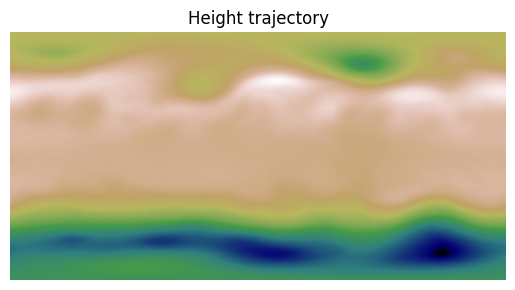

In [91]:
#Plot the trajectory of the height field for the first 50 time steps
whichtimes = np.arange(0,50)
trajectory(H[whichtimes], plot_height, title = "Height trajectory", fontsize = 12)

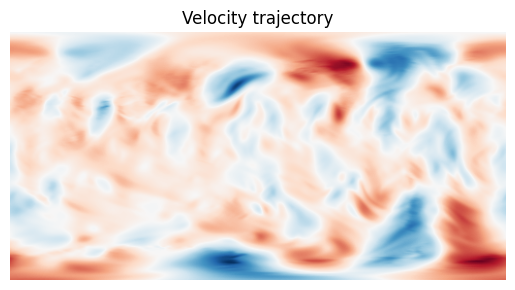

In [92]:
#Plot the trajectory of the velocity field for the first 50 time steps
whichtimes = np.arange(0,50)
trajectory(Utheta[whichtimes], plot_velocity, title = "Velocity trajectory", fontsize = 12)

## SENSOR DATA - fixed sensors 

In [93]:
# EXTRACT SENSORS DATA 

# We randomly select 3 sensors on the grid and extract their time series data from the height field H. 
nsensors = 3
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T

sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

Sensors coordinates:
 [[243 480]
 [208 434]
 [218  39]]
Sensors data shape:	 torch.Size([1008, 3])


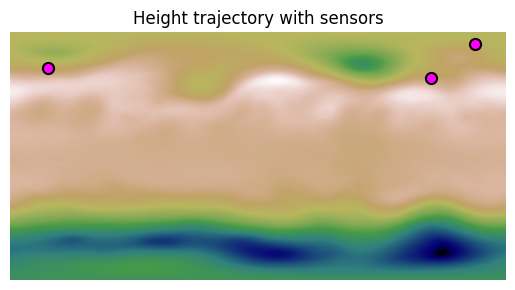

In [94]:
# TRAJECTORY WITH SENSORS (PLOT) 

def trajectory_with_sensors(ut, sensors_coordinates, title = None):
    
    for i in range(ut.shape[0]):
        plot_state(ut[i], cmap = "gist_earth")

        # Plot sensors locations on top of the height field
        for k in np.arange(nsensors):
            plt.plot(sensors_coordinates[k,1], sensors_coordinates[k,0], 'o', mfc = 'magenta', mec = 'black', ms = 8, mew = 1.5)
        
        plt.title(title)
        plt.axis('off')
        display(plt.gcf())
        plt.close()
        clc(wait=True)

whichtimes = np.arange(0, 50)
trajectory_with_sensors(H[whichtimes], sensors_coordinates, title = "Height trajectory with sensors")

## TRAIN VAL TEST split

In [95]:
np.random.seed(0)

# dimensions
ntrain = round(0.8 * ntimes)
nvalid = round(0.1 * ntimes)
ntest = ntimes - ntrain - nvalid

# split indices
idx_train = [i for i in range(ntimes) if i < ntrain]
idx_valid = [i for i in range(ntimes) if ntrain <= i < ntrain + nvalid]
idx_test = [i for i in range(ntimes) if i >= ntrain + nvalid]

# split
H_train, H_valid, H_test = H[idx_train], H[idx_valid], H[idx_test]
Utheta_train, Utheta_valid, Utheta_test = Utheta[idx_train], Utheta[idx_valid], Utheta[idx_test]
Uphi_train, Uphi_valid, Uphi_test = Uphi[idx_train], Uphi[idx_valid], Uphi[idx_test]
sensor_train, sensor_valid, sensor_test = sensors_data[idx_train], sensors_data[idx_valid], sensors_data[idx_test]

print("Number of training samples:\t", ntrain)
print("Number of validation samples:\t", nvalid)
print("Number of test samples:\t\t", ntest)

print("\nIN:")
print("sensor_train shape:\t", sensor_train.shape)

print("\nOUT:")
print("H_train shape:\t\t", H_train.shape)
print("Utheta_train shape:\t", Utheta_train.shape)
print("Uphi_train shape:\t", Uphi_train.shape)


Number of training samples:	 806
Number of validation samples:	 101
Number of test samples:		 101

IN:
sensor_train shape:	 torch.Size([806, 3])

OUT:
H_train shape:		 torch.Size([806, 131072])
Utheta_train shape:	 torch.Size([806, 131072])
Uphi_train shape:	 torch.Size([806, 131072])


## POD Reduction

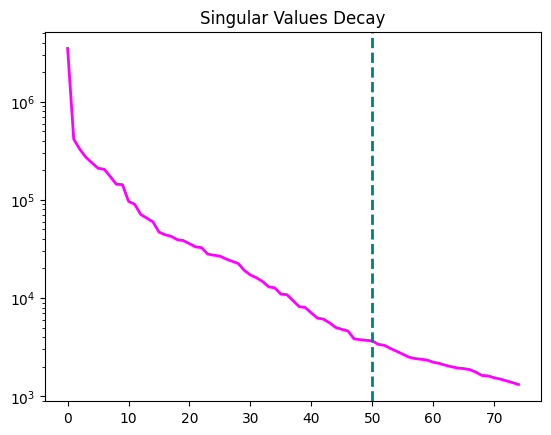

torch.Size([806, 131072])  -->  torch.Size([806, 50])
torch.Size([101, 131072])  -->  torch.Size([101, 50])
torch.Size([101, 131072])  -->  torch.Size([101, 50])


In [96]:
POD_modes = 50 # Number of POD modes

# Perform randomized SVD on the training data to compute the POD modes
W_POD, S_POD, V_POD = randomized_svd(H_train.numpy(), n_components = 75)

# Plot the decay of the singular values to visualize how much energy is captured by the POD modes
plt.semilogy(S_POD, color = 'magenta', linewidth = 2)
plt.axvline(POD_modes, color = 'teal', linestyle = '--', linewidth = 2)
plt.title("Singular Values Decay")
plt.show()

# Project the data onto the first POD modes to reduce dimensionality
VH_POD = V_POD[:POD_modes]
H_POD_train = H_train @ VH_POD.T
H_POD_valid = H_valid @ VH_POD.T
H_POD_test = H_test @ VH_POD.T

# Print the shapes of the original and POD-reduced training data to verify the dimensionality reduction 
print(H_train.shape, " --> ", H_POD_train.shape)
print(H_valid.shape, " --> ", H_POD_valid.shape)
print(H_test.shape, " --> ", H_POD_test.shape)

In [97]:
# Scale the sensor inputs to the range [0, 1] using MinMaxScaler (fit on train only)
scaler_sensors = MinMaxScaler()
scaler_sensors = scaler_sensors.fit(sensor_train)

# Transform sensor data and convert to tensors
sensor_train = torch.from_numpy(scaler_sensors.transform(sensor_train))
sensor_valid = torch.from_numpy(scaler_sensors.transform(sensor_valid))
sensor_test  = torch.from_numpy(scaler_sensors.transform(sensor_test))

# Scale the POD coefficients to the range [0, 1] using MinMaxScaler
scalerH_POD = MinMaxScaler()
scalerH_POD = scalerH_POD.fit(H_POD_train)

# Transform the POD coefficients and convert them to PyTorch tensors for use in the model
H_POD_train = torch.from_numpy(
    scalerH_POD.transform(H_POD_train).reshape(ntrain, POD_modes)
)
H_POD_valid = torch.from_numpy(
    scalerH_POD.transform(H_POD_valid).reshape(nvalid, POD_modes)
)
H_POD_test = torch.from_numpy(
    scalerH_POD.transform(H_POD_test).reshape(ntest, POD_modes)
)

# Print the shapes of the POD-reduced training, validation, and test data to verify the transformations
print("H_POD_train ", H_POD_train.shape)
print("H_POD_valid ", H_POD_valid.shape)
print("H_POD_test ", H_POD_test.shape)

H_POD_train  torch.Size([806, 50])
H_POD_valid  torch.Size([101, 50])
H_POD_test  torch.Size([101, 50])


## Benchmark

In [98]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 50

train_data_in = Padding(sensor_train.unsqueeze(0), lag).to(device)
valid_data_in = Padding(sensor_valid.unsqueeze(0), lag).to(device)
test_data_in = Padding(sensor_test.unsqueeze(0), lag).to(device)

train_data_out = Padding(H_POD_train.unsqueeze(0), 1).squeeze(1).to(device)
valid_data_out = Padding(H_POD_valid.unsqueeze(0), 1).squeeze(1).to(device)
test_data_out = Padding(H_POD_test.unsqueeze(0), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset = TimeSeriesDataset(test_data_in, test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")


Using device: cpu
Train dataset shape: 
torch.Size([806, 50, 3]) -> torch.Size([806, 50])
Validation dataset shape: 
torch.Size([101, 50, 3]) -> torch.Size([101, 50])
Test dataset shape: 
torch.Size([101, 50, 3]) -> torch.Size([101, 50])


In [99]:
model_args = dict(
    # Encoder
    encoder         = "vanilla_transformer",
    encoder_depth   = 1,
    d_model         = nsensors,   # input feature dim (one value per sensor)
    n_heads         = 8,
    dim_feedforward = 128,
    hidden_size     = 64,         # must be divisible by n_heads (32 / 4 = 8 ✓)
    input_length    = lag,

    # Decoder
    decoder         = "cnn",
    decoder_depth   = 3,
    output_size     = POD_modes,   # only H POD coefficients

    # Shared
    dropout         = 0.0,
    device          = device,
)
tshred = TSHRED(args=model_args)

In [100]:
train_errors, valid_errors = fit(
    tshred, train_dataset, valid_dataset, 
    batch_size = 64, epochs = 3000, lr = 1e-2, verbose = True, patience = 2500, scheduler_patience=500
)


Training:  84%|████████▎ | 2510/3000 [07:15<01:25,  5.76it/s, Train Error=26.109%, Val Error=82.235%, Patience=2499, Best Val Error=80.861%, LR=6.25e-04]

Early stopping at epoch 2511


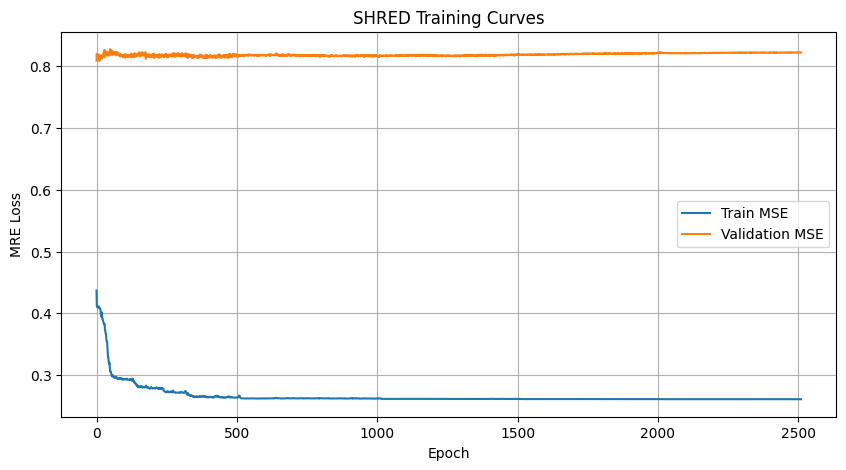

In [101]:
# PLOT TRAINING CURVES

plt.figure(figsize=(10, 5))
plt.plot(train_errors, label='Train MSE')
plt.plot(valid_errors, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('MRE Loss')
plt.title('SHRED Training Curves')
plt.legend()
plt.grid()
plt.show()

In [102]:
from src.utils import mre, num2p

# TSHRED PREDICTIONS
tshred.freeze()

train_data_out_hat = tshred(train_data_in).cpu()
valid_data_out_hat = tshred(valid_data_in).cpu()
test_data_out_hat  = tshred(test_data_in).cpu()

# Inverse-transform POD coefficients back to the full spatial field
VH = torch.from_numpy(VH_POD).float()   # (POD_modes, nheight)

H_hat_train = torch.from_numpy(scalerH_POD.inverse_transform(train_data_out_hat.detach().numpy())).float() @ VH
H_hat_valid = torch.from_numpy(scalerH_POD.inverse_transform(valid_data_out_hat.detach().numpy())).float() @ VH
H_hat_test  = torch.from_numpy(scalerH_POD.inverse_transform(test_data_out_hat.detach().numpy())).float()  @ VH

print("=== TSHRED (Transformer) - Height reconstruction ===")
print("Train MRE: %s" % num2p(mre(H[idx_train], H_hat_train)))
print("Valid MRE: %s" % num2p(mre(H[idx_valid], H_hat_valid)))
print("Test  MRE: %s" % num2p(mre(H[idx_test],  H_hat_test)))

=== TSHRED (Transformer) - Height reconstruction ===
Train MRE: 4.220%
Valid MRE: 29.639%
Test  MRE: 41.125%


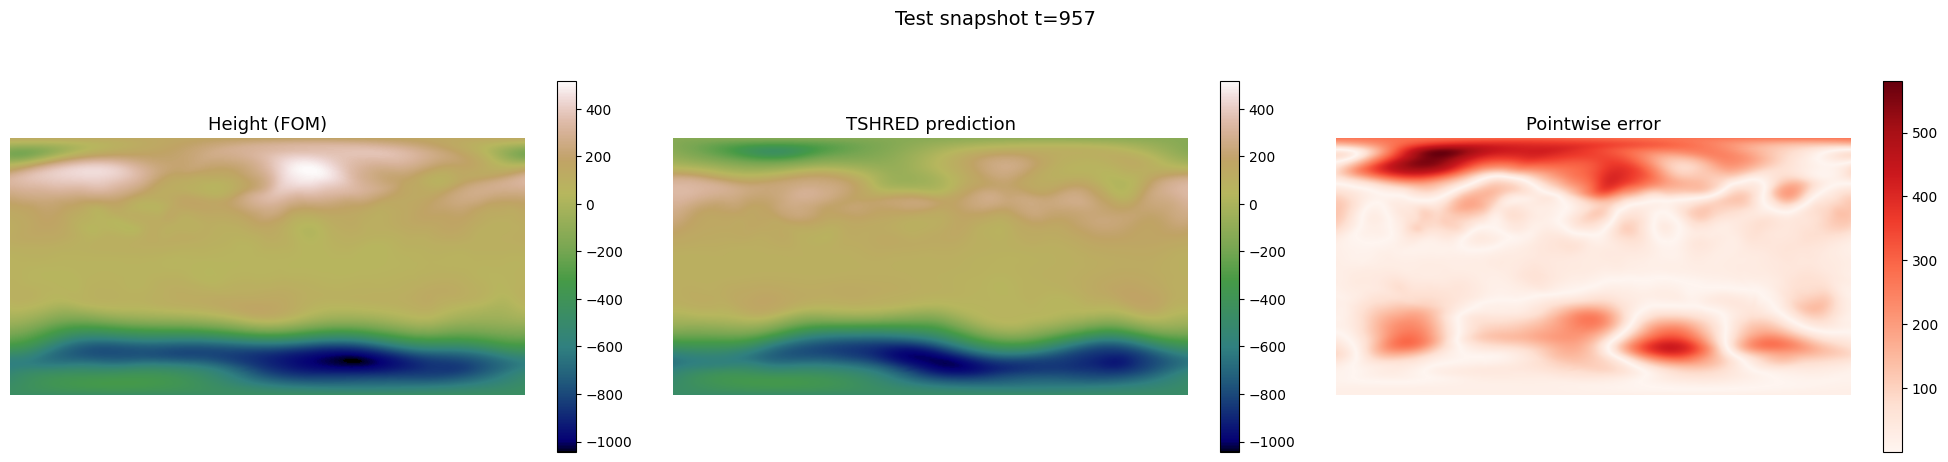

In [103]:
# FOM vs TSHRED RECONSTRUCTION - static snapshot comparison (same format as SHRED-ROM)

# Rebuild full H_hat over all time indices  
H_hat = torch.zeros(ntimes, nheight)
H_hat[idx_train] = H_hat_train
H_hat[idx_valid] = H_hat_valid
H_hat[idx_test]  = H_hat_test

t = idx_test[len(idx_test)//2]   # pick a representative test snapshot

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
titles = ("Height (FOM)", "TSHRED prediction", "Pointwise error")
fields = [H[t], H_hat[t], (H[t] - H_hat[t]).abs()]
cmaps  = ["gist_earth", "gist_earth", "Reds"]

vmin, vmax = H[t].min().item(), H[t].max().item()

for ax, field, title, cmap in zip(axes, fields, titles, cmaps):
    plt.sca(ax)
    im = ax.imshow(field.reshape(Lx, Ly), cmap=cmap,
                   vmin=(vmin if cmap != "Reds" else None),
                   vmax=(vmax if cmap != "Reds" else None),
                   origin='lower')
    plt.colorbar(im, ax=ax, shrink=0.85)
    ax.set_title(title, fontsize=13)
    ax.axis('off')

plt.suptitle(f"Test snapshot t={t}", fontsize=14)
plt.tight_layout()
plt.show()